<a href="https://colab.research.google.com/github/MelonG1t/Thesis-Entry-Assignment-Neural-Networks-and-the-Phase-Problem/blob/main/models_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Model and experiments**

import the data split into the validation and training sets

In [3]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import sys
import torch

PROJECT_DIR = Path(
    "/content/drive/MyDrive/neural-networks-phase"
)
DATA_DIR = PROJECT_DIR / "data"

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from data_processing import create_train_val_loaders

train_loader, val_loader = create_train_val_loaders(
    data_dir=DATA_DIR,
    batch_size=128,
    seed=42,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Mounted at /content/drive
Training batches: 391
Validation batches: 79


In [3]:

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/neural-networks-phase"
)

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Folder exists:", PROJECT_DIR.exists())



Project folder: /content/drive/MyDrive/neural-networks-phase
Folder exists: True


Creat the MLP structure

In [4]:

%%writefile /content/drive/MyDrive/neural-networks-phase/models.py

import torch
from torch import nn


class MLP(nn.Module):
    """A simple multilayer perceptron for Fashion-MNIST."""

    def __init__(self, num_classes=10):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            #nn.Dropout(p = 0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, images):
       return self.network(images)

Overwriting /content/drive/MyDrive/neural-networks-phase/models.py


Shape tests for the MLP model


In [ ]:
import sys
import importlib

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import models
importlib.reload(models)

model = models.MLP()

print(model)

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=10, bias=True)
  )
)


In [ ]:

import torch

# Get one batch from our existing training data loader.
images, labels = next(iter(train_loader))

# Tell PyTorch that we are only testing, not training.
model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)
print("Number of trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))


Input shape: torch.Size([128, 1, 28, 28])
Output shape: torch.Size([128, 10])
Labels shape: torch.Size([128])
Number of trainable parameters: 203530


Creat CNN structure

In [5]:

%%writefile -a /content/drive/MyDrive/neural-networks-phase/models.py


class CNN(nn.Module):
    """A convolutional neural network for Fashion-MNIST."""

    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            # Input: 1 x 28 x 28
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.1),

            # Input here: 32 x 14 x 14
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=0.25),
            nn.Linear(128, num_classes),
        )

    def forward(self, images):
        features = self.features(images)
        return self.classifier(features)


Appending to /content/drive/MyDrive/neural-networks-phase/models.py


Shape tests for the CNN model

In [ ]:

import importlib
import torch
import models

importlib.reload(models)

cnn = models.CNN()

print(cnn)

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [ ]:
cnn.eval()

with torch.no_grad():
    outputs = cnn(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in cnn.parameters() if p.requires_grad)
)


Input shape: torch.Size([128, 1, 28, 28])
Output shape: torch.Size([128, 10])
Trainable parameters: 421642



1. Pass a batch of images through the model.
2. Compare its scores with the correct labels using a loss function.
3. Calculate gradients using backpropagation.
4. Update the weights using an optimizer.
5. Measure training and validation accuracy and loss after each epoch.
6. Save the best model based on validation performance.

this creats the learning structure that we can later run different experiments on

In [16]:

%%writefile /content/drive/MyDrive/neural-networks-phase/training.py

import torch
from torch import nn


def run_epoch(model, loader, criterion, device, optimizer=None):
    """Run one training or evaluation epoch."""

    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        predictions = outputs.argmax(dim=1)
        total_correct += (predictions == labels).sum().item()
        total_examples += batch_size

    average_loss = total_loss / total_examples
    accuracy = total_correct / total_examples

    return average_loss, accuracy


def fit_model(
    model,
    train_loader,
    val_loader,
    epochs=10,
    learning_rate=0.001,
    device=None,
    patience=3,
    min_delta = 0.001,
):
    """Train a model and keep the weights with the best validation accuracy."""

    if device is None:
        device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
    }

    best_val_accuracy = -1.0
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(epochs):
        train_loss, train_accuracy = run_epoch(
            model, train_loader, criterion, device, optimizer
        )

        val_loss, val_accuracy = run_epoch(
            model, val_loader, criterion, device
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        improved = val_accuracy > best_val_accuracy + min_delta

        if improved:
            best_val_accuracy = val_accuracy
            best_epoch = epoch + 1
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"train loss: {train_loss:.4f} | "
            f"train acc: {train_accuracy:.2%} | "
            f"val loss: {val_loss:.4f} | "
            f"val acc: {val_accuracy:.2%}"
        )

        if epochs_without_improvement >= patience:
            print(
                f"Early stopping: no validation accuracy "
                f"improvement for {patience} epochs."
            )
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    model = model.to(device)
    history["best_epoch"] = best_epoch
    history["best_val_accuracy"] = best_val_accuracy

    print(
        f"Best validation accuracy: {best_val_accuracy:.2%} "
        f"(epoch {best_epoch})"
    )

    return model, history


Overwriting /content/drive/MyDrive/neural-networks-phase/training.py


Short control run of the MLP that everything works fine

In [ ]:

# Set seeds for a reproducible starting point.
import random
import numpy as np
import models
import training

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Create a fresh MLP.
mlp = models.MLP()

# Train it and record its performance.
mlp, mlp_history = training.fit_model(
    model=mlp,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=5,
    learning_rate=0.001,
)

print("Training finished.")


Epoch 01/5 | train loss: 0.5870 | train acc: 0.7962 | val loss: 0.4439 | val acc: 0.8438
Epoch 02/5 | train loss: 0.4202 | train acc: 0.8523 | val loss: 0.4057 | val acc: 0.8550
Epoch 03/5 | train loss: 0.3774 | train acc: 0.8655 | val loss: 0.3707 | val acc: 0.8664
Epoch 04/5 | train loss: 0.3534 | train acc: 0.8738 | val loss: 0.3577 | val acc: 0.8726
Epoch 05/5 | train loss: 0.3280 | train acc: 0.8824 | val loss: 0.3446 | val acc: 0.8747
Training finished.


Text(0.5, 0, 'Epoch')

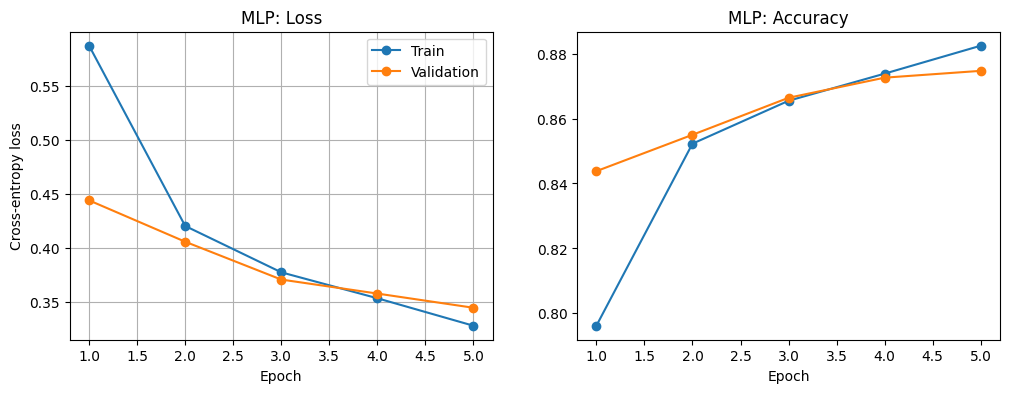

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(mlp_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss curves
axes[0].plot(epochs, mlp_history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs, mlp_history["val_loss"], marker="o", label="Validation")
axes[0].set_title("MLP: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy curves
axes[1].plot(epochs, mlp_history["train_accuracy"], marker="o", label="Train")
axes[1].plot(epochs, mlp_history["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("MLP: Accuracy")
axes[1].set_xlabel("Epoch")

This shows that everything so far works fine and our MLP modle learns even with 5 epochs of data

Added early stopping and ran on more epochs

Training of the MLP

In [ ]:

import sys
import importlib
import random
import numpy as np
import torch

PROJECT_DIR = "/content/drive/MyDrive/neural-networks-phase"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

import models
import training

importlib.reload(models)
importlib.reload(training)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Early stopping is ready.")


Device: cpu
Early stopping is ready.


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

mlp = models.MLP()

mlp, mlp_history = training.fit_model(
    model=mlp,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=15,
    learning_rate=0.001,
    patience=3,
    min_delta=0.001,
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    )

print("MLP best epoch:", mlp_history["best_epoch"])
print(
    "MLP best validation accuracy:",
    f'{mlp_history["best_val_accuracy"]:.2%}'
)

Epoch 01/15 | train loss: 0.5825 | train acc: 80.05% | val loss: 0.4575 | val acc: 83.84%
Epoch 02/15 | train loss: 0.4233 | train acc: 85.23% | val loss: 0.4120 | val acc: 85.12%
Epoch 03/15 | train loss: 0.3791 | train acc: 86.47% | val loss: 0.3815 | val acc: 86.36%
Epoch 04/15 | train loss: 0.3516 | train acc: 87.33% | val loss: 0.3799 | val acc: 86.13%
Epoch 05/15 | train loss: 0.3282 | train acc: 88.26% | val loss: 0.3661 | val acc: 86.37%
Epoch 06/15 | train loss: 0.3118 | train acc: 88.69% | val loss: 0.3298 | val acc: 87.98%
Epoch 07/15 | train loss: 0.2981 | train acc: 89.22% | val loss: 0.3215 | val acc: 88.17%
Epoch 08/15 | train loss: 0.2832 | train acc: 89.66% | val loss: 0.3190 | val acc: 88.44%
Epoch 09/15 | train loss: 0.2708 | train acc: 90.09% | val loss: 0.3281 | val acc: 87.99%
Epoch 10/15 | train loss: 0.2602 | train acc: 90.49% | val loss: 0.3111 | val acc: 88.71%
Epoch 11/15 | train loss: 0.2538 | train acc: 90.75% | val loss: 0.3097 | val acc: 88.47%
Epoch 12/1

Training of the CNN

In [ ]:

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

cnn = models.CNN()

cnn, cnn_history = training.fit_model(
    model=cnn,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=15,
    learning_rate=0.001,
    patience=3,
    min_delta=0.001,
    device=device,
)

print("CNN best epoch:", cnn_history["best_epoch"])
print(
    "CNN best validation accuracy:",
    f'{cnn_history["best_val_accuracy"]:.2%}'
)


Epoch 01/15 | train loss: 0.6006 | train acc: 78.06% | val loss: 0.3829 | val acc: 85.76%
Epoch 02/15 | train loss: 0.3695 | train acc: 86.66% | val loss: 0.3124 | val acc: 88.66%
Epoch 03/15 | train loss: 0.3210 | train acc: 88.42% | val loss: 0.3104 | val acc: 88.48%
Epoch 04/15 | train loss: 0.2878 | train acc: 89.55% | val loss: 0.2672 | val acc: 90.12%
Epoch 05/15 | train loss: 0.2674 | train acc: 90.18% | val loss: 0.2636 | val acc: 90.26%
Epoch 06/15 | train loss: 0.2496 | train acc: 90.82% | val loss: 0.2493 | val acc: 90.82%
Epoch 07/15 | train loss: 0.2349 | train acc: 91.40% | val loss: 0.2469 | val acc: 91.26%
Epoch 08/15 | train loss: 0.2187 | train acc: 92.06% | val loss: 0.2399 | val acc: 90.99%
Epoch 09/15 | train loss: 0.2056 | train acc: 92.45% | val loss: 0.2269 | val acc: 91.74%
Epoch 10/15 | train loss: 0.1924 | train acc: 93.04% | val loss: 0.2258 | val acc: 91.78%
Epoch 11/15 | train loss: 0.1798 | train acc: 93.41% | val loss: 0.2317 | val acc: 91.33%
Epoch 12/1

PLoting accuracz MLP vs CNN

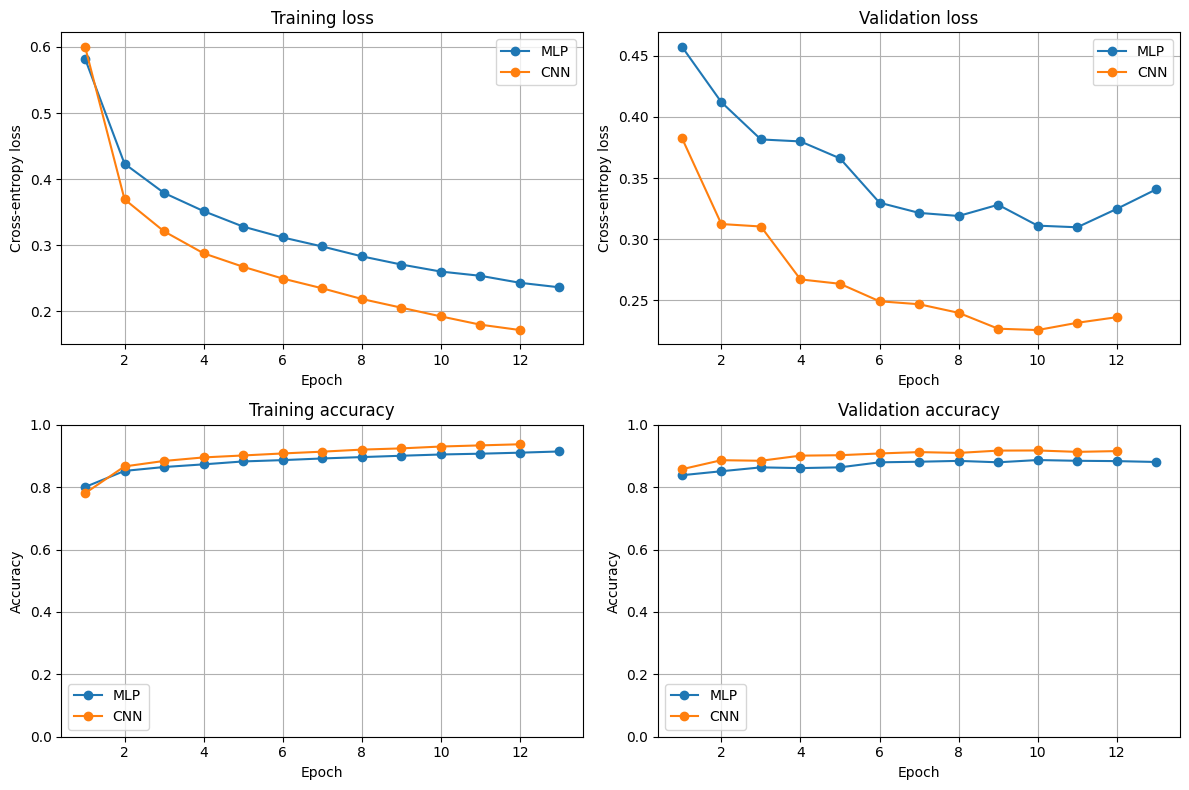

In [37]:

import matplotlib.pyplot as plt


def plot_comparison(mlp_history, cnn_history):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    histories = [
        ("MLP", mlp_history),
        ("CNN", cnn_history),
    ]

    for name, history in histories:
        epochs = range(1, len(history["train_loss"]) + 1)

        axes[0, 0].plot(
            epochs, history["train_loss"], marker="o",
            label=name
        )
        axes[0, 1].plot(
            epochs, history["val_loss"], marker="o",
            label=name
        )
        axes[1, 0].plot(
            epochs, history["train_accuracy"], marker="o",
            label=name
        )
        axes[1, 1].plot(
            epochs, history["val_accuracy"], marker="o",
            label=name
        )

    titles = [
        "Training loss",
        "Validation loss",
        "Training accuracy",
        "Validation accuracy",
    ]

    for ax, title in zip(axes.flat, titles):
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.grid(True)
        ax.legend()

    axes[0, 0].set_ylabel("Cross-entropy loss")
    axes[0, 1].set_ylabel("Cross-entropy loss")
    axes[1, 0].set_ylabel("Accuracy")
    axes[1, 1].set_ylabel("Accuracy")

    axes[1, 0].set_ylim(0, 1)
    axes[1, 1].set_ylim(0, 1)

    plt.tight_layout()
    plt.show()


plot_comparison(mlp_history, cnn_history)


In [36]:

import json
from pathlib import Path

RESULTS_DIR = Path(PROJECT_DIR) / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

summary = {
    "MLP": {
        "best_epoch": int(mlp_history["best_epoch"]),
        "best_validation_accuracy": float(
            mlp_history["best_val_accuracy"]
        ),
    },
    "CNN": {
        "best_epoch": int(cnn_history["best_epoch"]),
        "best_validation_accuracy": float(
            cnn_history["best_val_accuracy"]
        ),
    },
}

with open(RESULTS_DIR / "baseline_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))


{
  "MLP": {
    "best_epoch": 10,
    "best_validation_accuracy": 0.8871
  },
  "CNN": {
    "best_epoch": 9,
    "best_validation_accuracy": 0.9174
  }
}


Diferent hyperparameters MLP and CNN



MLP - added dropout p = 0.5
and added learning-rate schedule CosineAnnealingLR (slow decay)

In [17]:
import torch
import random
import numpy as np
import models
import sys
import importlib
import training



SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

mlp = models.MLP()

mlp, mlp_history = training.fit_model(
    model=mlp,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=15,
    learning_rate=0.01,
    patience=3,
    min_delta=0.001,
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    )

print("MLP best epoch:", mlp_history["best_epoch"])
print(
    "MLP best validation accuracy:",
    f'{mlp_history["best_val_accuracy"]:.2%}'
)

Epoch 01/15 | train loss: 0.5279 | train acc: 81.12% | val loss: 0.4062 | val acc: 85.33%
Epoch 02/15 | train loss: 0.4028 | train acc: 85.48% | val loss: 0.3886 | val acc: 86.18%
Epoch 03/15 | train loss: 0.3655 | train acc: 86.71% | val loss: 0.3691 | val acc: 86.52%
Epoch 04/15 | train loss: 0.3527 | train acc: 87.17% | val loss: 0.3718 | val acc: 86.13%
Epoch 05/15 | train loss: 0.3363 | train acc: 87.59% | val loss: 0.3607 | val acc: 87.02%
Epoch 06/15 | train loss: 0.3242 | train acc: 88.08% | val loss: 0.3646 | val acc: 86.71%
Epoch 07/15 | train loss: 0.3207 | train acc: 88.38% | val loss: 0.3761 | val acc: 86.34%
Epoch 08/15 | train loss: 0.3115 | train acc: 88.39% | val loss: 0.3621 | val acc: 87.32%
Epoch 09/15 | train loss: 0.3107 | train acc: 88.46% | val loss: 0.3720 | val acc: 86.85%
Epoch 10/15 | train loss: 0.2978 | train acc: 88.97% | val loss: 0.3598 | val acc: 87.13%
Epoch 11/15 | train loss: 0.2975 | train acc: 88.93% | val loss: 0.3618 | val acc: 87.44%
Epoch 12/1

CNN - added dropout 0.1 -> 0.2 -> 0.25

In [20]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

cnn = models.CNN()

cnn, cnn_history = training.fit_model(
    model=cnn,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=25,
    learning_rate=0.001,
    patience=3,
    min_delta=0.001,
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    )
print("CNN best epoch:", cnn_history["best_epoch"])
print(
    "CNN best validation accuracy:",
    f'{cnn_history["best_val_accuracy"]:.2%}'
)


Epoch 01/25 | train loss: 0.6222 | train acc: 77.44% | val loss: 0.3858 | val acc: 85.71%
Epoch 02/25 | train loss: 0.3913 | train acc: 86.03% | val loss: 0.3190 | val acc: 88.34%
Epoch 03/25 | train loss: 0.3370 | train acc: 87.96% | val loss: 0.3017 | val acc: 89.11%
Epoch 04/25 | train loss: 0.3072 | train acc: 88.93% | val loss: 0.2795 | val acc: 89.74%
Epoch 05/25 | train loss: 0.2882 | train acc: 89.53% | val loss: 0.2629 | val acc: 90.47%
Epoch 06/25 | train loss: 0.2690 | train acc: 90.35% | val loss: 0.2492 | val acc: 90.88%
Epoch 07/25 | train loss: 0.2550 | train acc: 90.71% | val loss: 0.2496 | val acc: 90.92%
Epoch 08/25 | train loss: 0.2396 | train acc: 91.18% | val loss: 0.2427 | val acc: 90.97%
Epoch 09/25 | train loss: 0.2291 | train acc: 91.63% | val loss: 0.2342 | val acc: 91.10%
Epoch 10/25 | train loss: 0.2169 | train acc: 92.12% | val loss: 0.2249 | val acc: 91.55%
Epoch 11/25 | train loss: 0.2077 | train acc: 92.24% | val loss: 0.2316 | val acc: 91.65%
Epoch 12/2

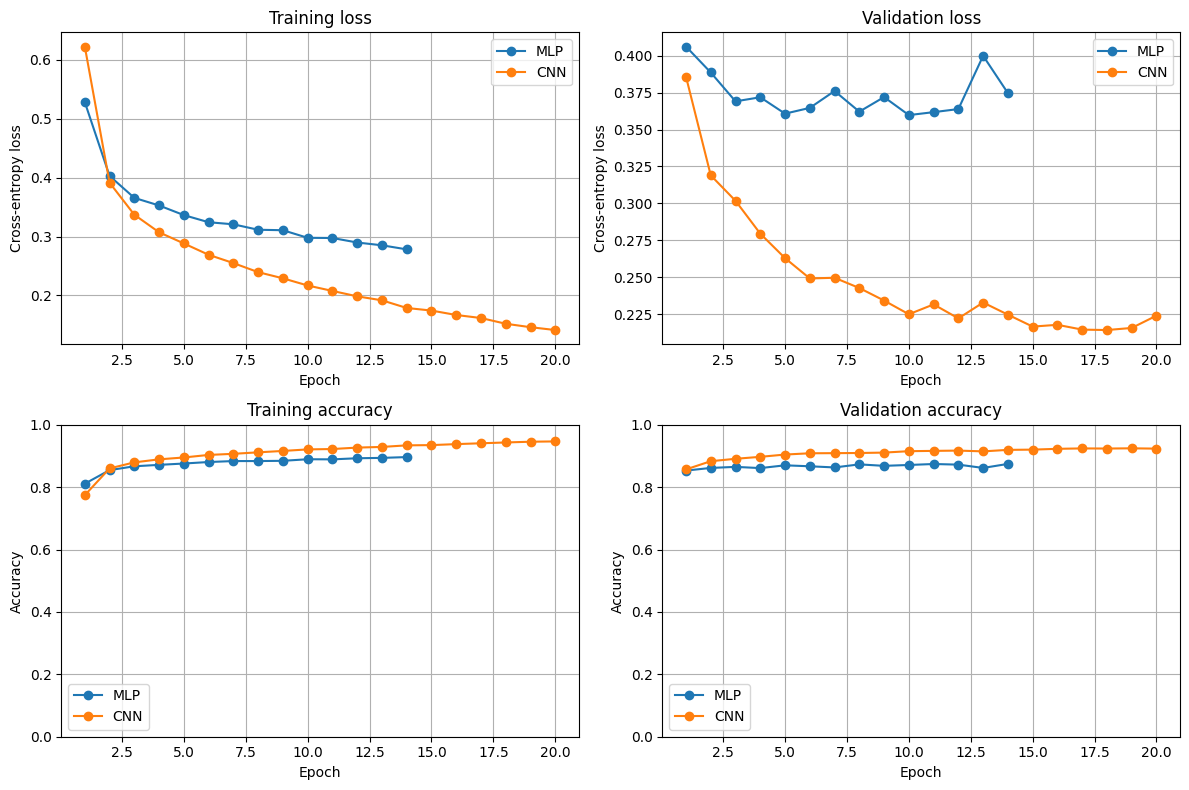

In [21]:
import matplotlib.pyplot as plt


def plot_comparison(mlp_history, cnn_history):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    histories = [
        ("MLP", mlp_history),
        ("CNN", cnn_history),
    ]

    for name, history in histories:
        epochs = range(1, len(history["train_loss"]) + 1)

        axes[0, 0].plot(
            epochs, history["train_loss"], marker="o",
            label=name
        )
        axes[0, 1].plot(
            epochs, history["val_loss"], marker="o",
            label=name
        )
        axes[1, 0].plot(
            epochs, history["train_accuracy"], marker="o",
            label=name
        )
        axes[1, 1].plot(
            epochs, history["val_accuracy"], marker="o",
            label=name
        )

    titles = [
        "Training loss",
        "Validation loss",
        "Training accuracy",
        "Validation accuracy",
    ]

    for ax, title in zip(axes.flat, titles):
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.grid(True)
        ax.legend()

    axes[0, 0].set_ylabel("Cross-entropy loss")
    axes[0, 1].set_ylabel("Cross-entropy loss")
    axes[1, 0].set_ylabel("Accuracy")
    axes[1, 1].set_ylabel("Accuracy")

    axes[1, 0].set_ylim(0, 1)
    axes[1, 1].set_ylim(0, 1)

    plt.tight_layout()
    plt.show()


plot_comparison(mlp_history, cnn_history)